Generated 1000 samples


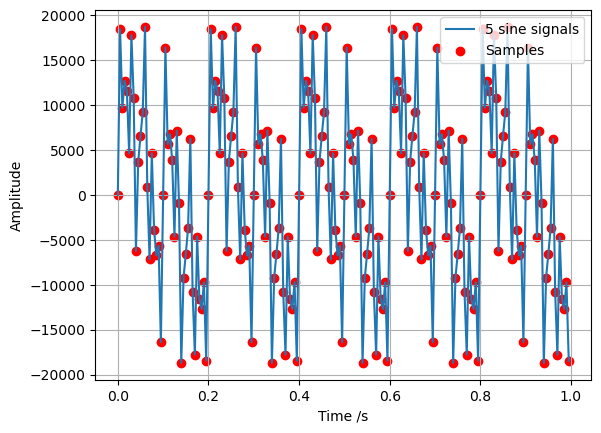

In [ ]:
#-------------------------------------------------------
#-- Titel       : Signalerzeugung 
#-------------------------------------------------------
#-- Projekt     : Vorabklärung TB
#-- Filename    : signal_generator.ipynb
#-- Autor       : Stefan Foltrauer
#-- Letze Änderungen : 17.10.2026
#-------------------------------------------------------
#-- Beschreibung: 
#-- Dieses Skript erzeugt ein Testsignal und speichert es in einer Textdatei.
#-------------------------------------------------------
# import of the required libraries
import numpy as np                  
import matplotlib.pyplot as plt     

fs = 200  # Sampling frequency: 200 Hz
samples = 1000 # Number of samples to generate
t = np.arange(samples) / fs    # Erzeugt die Zeitwerte für alle Samples
##########################################################################################
#erste Testsignal
frequency = 10  # Frequenz vom Sinussignal in Hz
#note: Wir werden Zweierkompliment verwenden, da das die Addition und Subtraktion von Zahlen vereinfacht.
#insbesonder wird weniger Hardware benötigt, um die Addition und Subtraktion von Zahlen zu implementieren. Das ist von Vorteil beim ASCI design.
m=2**16 # Anzahl der möglichen Werte (16 Bit)
amplitude = (m/2) -1                   # Maximale Amplitude von -32767 bis 32767 (für 16 Bit) statt -32768 bis 32767 da der Sinus symetrisch ist.

###########################################################################################
#2tes Testsignal
# Frequenzen der 5 Sinussignale
frequencies = [5, 10, 20, 40, 70]

# Amplitude pro Sinussignal
amplitude_each = amplitude / 5

# Kombination der 5 Sinussignale
signal = (amplitude_each * np.sin(2 * np.pi * frequencies[0] * t) +amplitude_each * np.sin(2 * np.pi * frequencies[1] * t) +amplitude_each * np.sin(2 * np.pi * frequencies[2] * t) +amplitude_each * np.sin(2 * np.pi * frequencies[3] * t) +amplitude_each * np.sin(2 * np.pi * frequencies[4] * t))

#signal = amplitude * np.sin(2 * np.pi * frequency * t)   # Sinussignal berechnen

signal = signal.astype(int)         # Signalwerte in ganze Zahlen umwandeln um sicher zu gehen

np.savetxt("input_signal.txt", signal, fmt="%d")          # Werte als Ganzzahlen speichern

print("Generated", samples, "samples")                    # Meldung ausgeben

# Plotting the signal für ein besseres Verständnis
t_smooth = np.linspace(0, t[199], 2000)                   # Viele Zeitpunkte für glatten Sinus
sin_smooth = amplitude * np.sin(2 * np.pi * frequency * t_smooth)  # Glatten Sinus berechnen

#plt.plot(t_smooth, sin_smooth, label="Original sine")     # Idealen Sinus
plt.plot(t[:200], signal[:200], label="5 sine signals")
plt.scatter(t[:200], signal[:200],color="red", label="Samples")       # Erste 200 Samples als Punkte zeichnen

plt.xlabel("Time /s")               
plt.ylabel("Amplitude")             
plt.legend()                        
plt.grid()                           
plt.show()                          